### Checking Data and It's Quality

In [47]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_csv('export.csv') 

df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,1N4AZ1CP3K,King,Shoreline,WA,98155.0,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,150.0,32.0,168526641,POINT (-122.30304 47.75494),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303302e+10
1,WBY8P4C51K,King,Kirkland,WA,98033.0,2019,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,126.0,48.0,9418181,POINT (-122.2066 47.67887),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
2,3FA6P0SU8G,Snohomish,Lynnwood,WA,98036.0,2016,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,1.0,172853495,POINT (-122.29245 47.82557),PUGET SOUND ENERGY INC,5.306105e+10
3,5YJ3E1EB3N,Yakima,Wapato,WA,98951.0,2022,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,15.0,204768175,POINT (-120.42083 46.44779),PACIFICORP,5.307794e+10
4,WBY1Z2C53F,King,Renton,WA,98055.0,2015,BMW,I3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,81.0,11.0,269262920,POINT (-122.19488 47.44034),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10


In [48]:
df.info() 


df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299705 entries, 0 to 299704
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         299705 non-null  object 
 1   County                                             299694 non-null  object 
 2   City                                               299694 non-null  object 
 3   State                                              299705 non-null  object 
 4   Postal Code                                        299694 non-null  float64
 5   Model Year                                         299705 non-null  int64  
 6   Make                                               299705 non-null  object 
 7   Model                                              299705 non-null  object 
 8   Electric Vehicle Type                              299705 non-null  object

,Postal Code,Model Year,Electric Range,Legislative District,DOL Vehicle ID,2020 GEOID
count,299694.000000,299705.000000,299679.000000,298915.000000,2.997050e+05,2.996940e+05
mean,98176.001962,2022.344666,36.663313,28.754589,2.509924e+08,5.296742e+10
std,2652.053836,3.093007,76.034423,14.892388,6.238702e+07,1.687605e+09
min,1030.000000,1999.000000,0.000000,1.000000,4.469000e+03,1.001020e+09
25%,98052.000000,2021.000000,0.000000,17.000000,2.283017e+08,5.303301e+10
50%,98134.000000,2023.000000,0.000000,32.000000,2.679271e+08,5.303303e+10
75%,98391.000000,2024.000000,32.000000,42.000000,2.845359e+08,5.305394e+10
max,99801.000000,2027.000000,337.000000,49.000000,4.791150e+08,6.601095e+10


In [49]:
print(df.duplicated().sum())

df.isnull().mean()

0


VIN (1-10)                                           0.000000
County                                               0.000037
City                                                 0.000037
State                                                0.000000
Postal Code                                          0.000037
Model Year                                           0.000000
Make                                                 0.000000
Model                                                0.000000
Electric Vehicle Type                                0.000000
Clean Alternative Fuel Vehicle (CAFV) Eligibility    0.000000
Electric Range                                       0.000087
Legislative District                                 0.002636
DOL Vehicle ID                                       0.000000
Vehicle Location                                     0.000067
Electric Utility                                     0.000037
2020 GEOID                                           0.000037
dtype: f

### More About the Data

In [50]:
df["Make"].value_counts(ascending=False)

Make
TESLA                     122981
CHEVROLET                  20236
FORD                       16118
NISSAN                     16053
KIA                        14776
TOYOTA                     13998
BMW                        12356
HYUNDAI                    12351
RIVIAN                      9817
VOLVO                       8187
VOLKSWAGEN                  7919
JEEP                        6177
AUDI                        6138
SUBARU                      3640
CHRYSLER                    3634
MERCEDES-BENZ               3491
HONDA                       3266
CADILLAC                    2883
LEXUS                       2188
PORSCHE                     2152
POLESTAR                    1696
MAZDA                       1693
MITSUBISHI                  1303
MINI                        1261
LUCID                        916
FIAT                         857
GMC                          623
GENESIS                      555
DODGE                        498
LINCOLN                      494
ACURA

In [51]:
df.groupby('Electric Vehicle Type').groups.keys()

dict_keys(['Battery Electric Vehicle (BEV)', 'Plug-in Hybrid Electric Vehicle (PHEV)'])

In [52]:
df.groupby('State').groups.keys()

dict_keys(['AE', 'AK', 'AL', 'AR', 'AZ', 'BC', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL', 'GA', 'GU', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OR', 'PA', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'WA', 'WI', 'WY'])

In [53]:
df.groupby('State').size().sort_values(ascending=False)

State
WA    298916
CA       180
VA       105
MD        46
TX        46
FL        44
OR        28
NV        27
CO        25
AZ        25
NC        20
IL        19
GA        17
IN        14
NY        14
ID        12
MO        11
NJ        11
DC        10
TN        10
AL         9
PA         8
MI         8
MA         8
NE         7
BC         6
CT         6
SC         5
NM         5
RI         5
KS         5
KY         5
OH         5
AE         4
WI         4
NH         4
LA         4
MN         4
HI         4
UT         3
AR         2
IA         2
SD         2
WY         2
GU         2
ME         2
DE         1
AK         1
MS         1
MT         1
dtype: int64

In [54]:
df.groupby('Model')['Model Year'].min().sort_values()

Model
RANGER        1999
RAV4          2002
ROADSTER      2008
WHEEGO        2010
CITY          2011
              ... 
POLESTAR 4    2026
ROGUE         2026
TEMERARIO     2026
BOLT          2027
R2            2027
Name: Model Year, Length: 202, dtype: int64

In [55]:
result = df.groupby('Model').agg(
    Make=('Make', 'first'),
    Launch_Year=('Model Year', 'min')
).reset_index()


result.sort_values('Launch_Year')

,Model,Make,Launch_Year
146,RANGER,FORD,1999
147,RAV4,TOYOTA,2002
152,ROADSTER,TESLA,2008
192,WHEEGO,WHEEGO ELECTRIC CARS,2010
39,CITY,TH!NK,2011
...,...,...,...
131,POLESTAR 4,POLESTAR,2026
153,ROGUE,NISSAN,2026
177,TEMERARIO,LAMBORGHINI,2026
26,BOLT,CHEVROLET,2027


### Want to see Tesla(Model)

In [56]:
tesla = df[df["Make"].str.strip().str.upper() == "TESLA"]

# Count of each model
model_counts = tesla["Model"].value_counts()
print(model_counts)

# As a clean DataFrame (good for saving or plotting)
model_counts = (
    tesla["Model"]
    .value_counts()
    .reset_index()
)
model_counts.columns = ["Model", "Count"]
print(model_counts)

# With percentage share
model_share = tesla["Model"].value_counts(normalize=True).mul(100).round(2)
print(model_share)


Model
MODEL Y       66545
MODEL 3       39391
MODEL S        7873
MODEL X        7177
CYBERTRUCK     1954
ROADSTER         41
Name: count, dtype: int64
        Model  Count
0     MODEL Y  66545
1     MODEL 3  39391
2     MODEL S   7873
3     MODEL X   7177
4  CYBERTRUCK   1954
5    ROADSTER     41
Model
MODEL Y       54.11
MODEL 3       32.03
MODEL S        6.40
MODEL X        5.84
CYBERTRUCK     1.59
ROADSTER       0.03
Name: proportion, dtype: float64


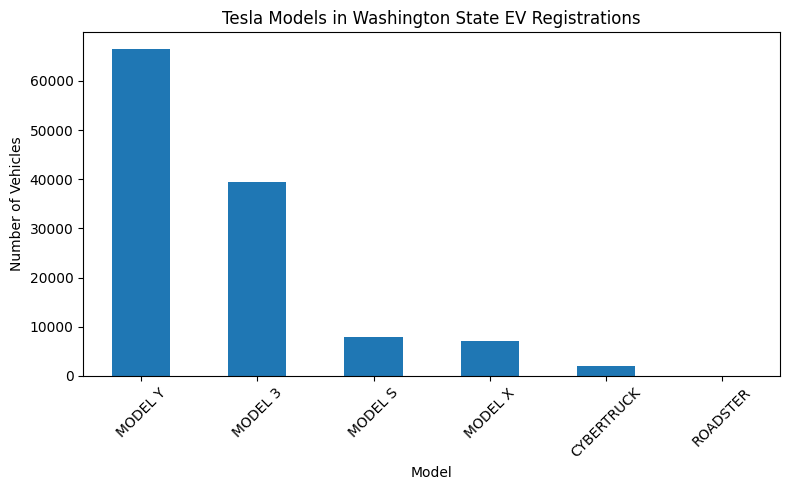

In [57]:
model_counts.plot(kind="bar", x="Model", y="Count", legend=False, figsize=(8, 5))
plt.title("Tesla Models in Washington State EV Registrations")
plt.ylabel("Number of Vehicles")
plt.xticks(rotation=45)
plt.tight_layout()

### Just want to see the Electric vehicle type

In [ ]:
df['Electric Vehicle Type'].value_counts()

"""  
1. Battery Electric Vehicle (BEV) has more type of vehicle then Plug-in Hybrid Electric Vehicle (PHEV).
2. If we want to gain some profit, then we need to do more focus on 'BEV' type vehicles.
3. Here we see clear 80.7% market is captured by 'BEV' type charging vehicles.

"""

Electric Vehicle Type
Battery Electric Vehicle (BEV)            241724
Plug-in Hybrid Electric Vehicle (PHEV)     57981
Name: count, dtype: int64

<Axes: ylabel='count'>

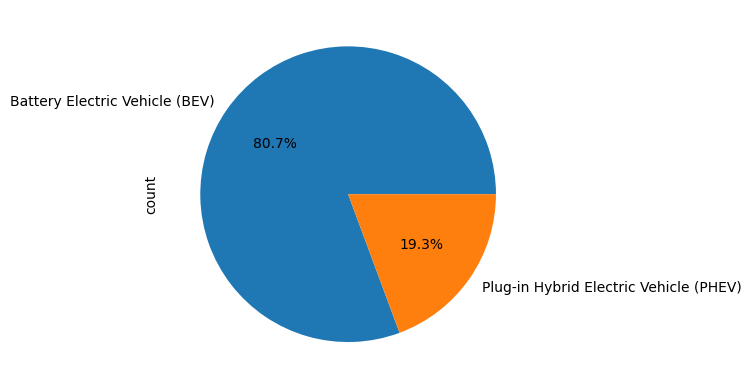

In [63]:
df['Electric Vehicle Type'].value_counts().plot(kind='pie', autopct='%1.1f%%')

### Electric Utility

In [ ]:
df['Electric Utility'].value_counts()

""" 
1. PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA) has highest utility.
2. This utility company has 34.7% market domainace . 

"""

Electric Utility
PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)                                               103988
PUGET SOUND ENERGY INC                                                                       63791
CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA)                                                 48888
BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF CLARK COUNTY - (WA)                             18318
BONNEVILLE POWER ADMINISTRATION||CITY OF TACOMA - (WA)||PENINSULA LIGHT COMPANY              13964
                                                                                             ...  
CITY OF SEATTLE - (WA)                                                                           1
BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF ASOTIN COUNTY                                       1
BONNEVILLE POWER ADMINISTRATION||PENINSULA LIGHT COMPANY                                         1
BONNEVILLE POWER ADMINISTRATION||PUD NO 1 OF CLALLAM COUNTY|PUD NO 1 OF JEFFERSON COUNTY    

In [76]:
# df['Electric Utility'].value_counts().plot(kind='pie', autopct='%1.1f%%')


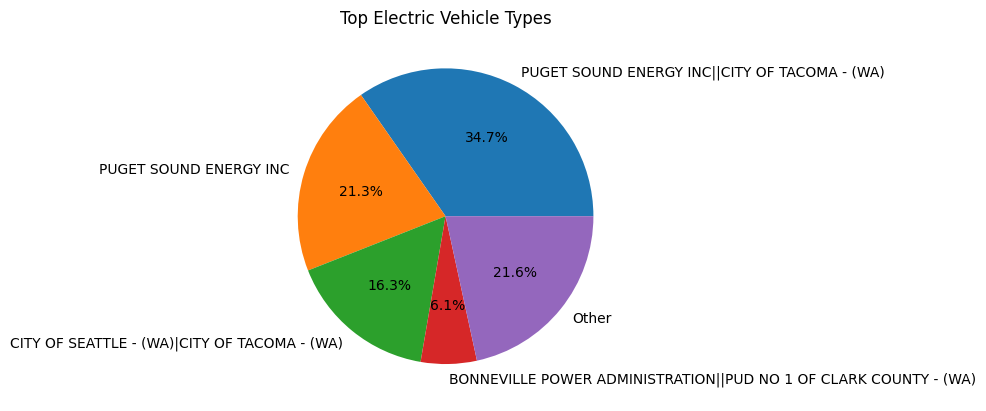

In [83]:
counts = df['Electric Utility'].value_counts()

# 2. Keep the top 4 categories (you can change this number)
top_counts = counts.nlargest(4)

# 3. Sum the remaining categories into an 'Other' slice
other_counts = pd.Series({'Other': counts.iloc[4:].sum()})

# 4. Combine them and plot
final_counts = pd.concat([top_counts, other_counts])
final_counts.plot(kind='pie', autopct='%1.1f%%', ylabel='')

plt.title('Top Electric Vehicle Types')
plt.show()

### Visualization 

In [ ]:
# df['Make'].value_counts().plot(kind='bar') 